In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [7]:
df = pd.read_csv("data/train.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
df.head()


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [9]:
df.shape

(913000, 4)

In [10]:
df.head(10)

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10
5,2013-01-06,1,1,12
6,2013-01-07,1,1,10
7,2013-01-08,1,1,9
8,2013-01-09,1,1,12
9,2013-01-10,1,1,9


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 36.6 MB


In [12]:
df.describe()

,store,item,sales
count,913000.000000,913000.000000,913000.000000
mean,5.500000,25.500000,52.250287
std,2.872283,14.430878,28.801144
min,1.000000,1.000000,0.000000
25%,3.000000,13.000000,30.000000
50%,5.500000,25.500000,47.000000
75%,8.000000,38.000000,70.000000
max,10.000000,50.000000,231.000000


In [13]:
df.isnull().sum()

date     0
store    0
item     0
sales    0
dtype: int64

In [14]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [15]:
print("Unique stores:", df['store'].nunique())
print("Unique items:", df['item'].nunique())
print("Unique dates:", df['date'].nunique())


Unique stores: 10
Unique items: 50
Unique dates: 1826


In [16]:
df.groupby(['store', 'item']).size().describe()

count     500.0
mean     1826.0
std         0.0
min      1826.0
25%      1826.0
50%      1826.0
75%      1826.0
max      1826.0
dtype: float64

In [17]:
df['date'] = pd.to_datetime(df['date'])

print("Data type:", df['date'].dtype)
print("Start date:", df['date'].min())
print("End date:", df['date'].max())


Data type: datetime64[us]
Start date: 2013-01-01 00:00:00
End date: 2017-12-31 00:00:00


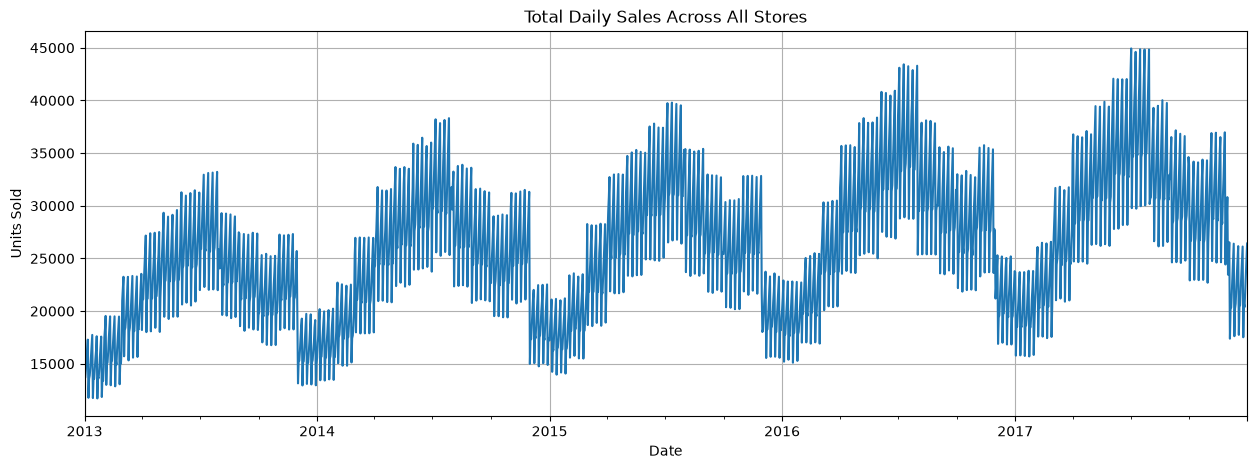

In [18]:
daily_sales = df.groupby('date')['sales'].sum()

plt.figure(figsize=(15, 5))
daily_sales.plot()

plt.title("Total Daily Sales Across All Stores")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.grid(True)
plt.show()

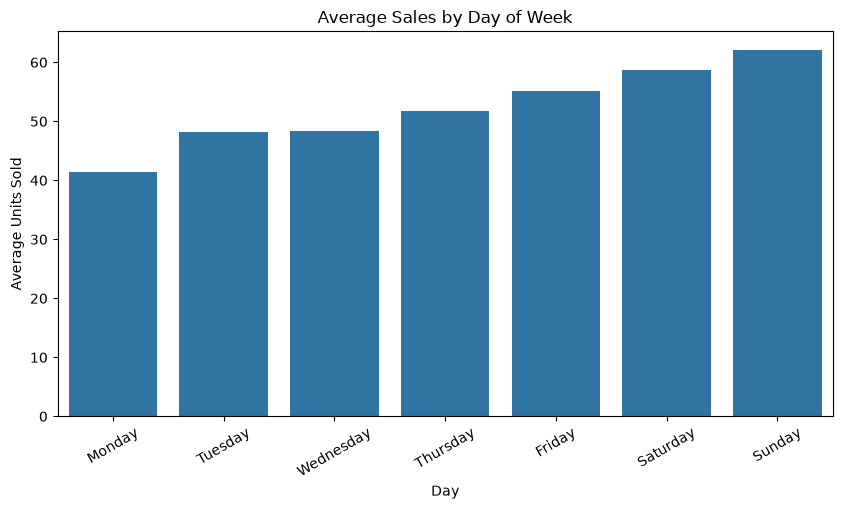

In [19]:
df['day_name'] = df['date'].dt.day_name()

weekly_sales = df.groupby('day_name')['sales'].mean()

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekly_sales = weekly_sales.reindex(day_order)

plt.figure(figsize=(10, 5))
sns.barplot(x=weekly_sales.index, y=weekly_sales.values)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=30)
plt.show()

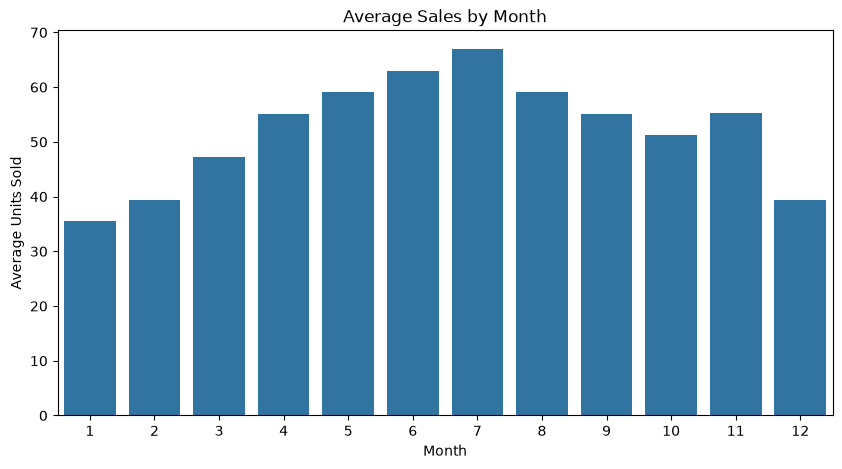

In [20]:
df['month'] = df['date'].dt.month

monthly_sales = df.groupby('month')['sales'].mean()

plt.figure(figsize=(10, 5))
sns.barplot(x=monthly_sales.index, y=monthly_sales.values)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.show()

In [21]:
weekly_sales.sort_values(ascending=False)

day_name
Sunday       62.143333
Saturday     58.662697
Friday       55.157249
Thursday     51.723218
Wednesday    48.368506
Tuesday      48.225908
Monday       41.429638
Name: sales, dtype: float64

In [22]:
monthly_sales.sort_values(ascending=False)

month
7     66.998619
6     63.025480
5     59.128219
8     59.105226
11    55.218080
4     55.152893
9     55.072760
10    51.193806
3     47.305574
2     39.378397
12    39.365265
1     35.524503
Name: sales, dtype: float64

In [23]:
df['year'] = df['date'].dt.year

yearly_sales = df.groupby('year')['sales'].mean()
yearly_sales

year
2013    43.513660
2014    50.057436
2015    52.256915
2016    56.596503
2017    58.815014
Name: sales, dtype: float64

In [24]:
store_sales = df.groupby('store')['sales'].mean().sort_values(ascending=False)
store_sales

store
2     67.033165
8     64.142048
3     59.530602
10    58.709288
9     55.049025
4     54.902946
1     47.268379
5     39.770164
6     39.733516
7     36.363735
Name: sales, dtype: float64

In [25]:
item_sales = df.groupby('item')['sales'].mean().sort_values(ascending=False)
item_sales

item
15    88.030778
28    87.881325
13    84.316594
18    84.275794
25    80.686418
45    80.584173
38    80.521906
22    80.502245
36    77.028916
8     76.950055
10    73.227437
11    69.656353
12    69.634940
29    69.618839
33    69.560953
24    66.044633
50    65.882202
35    65.801807
14    58.681873
31    58.644304
46    58.639869
2     58.574151
7     58.531051
6     58.503888
9     51.389869
48    51.352848
43    51.294359
26    47.644085
20    47.515936
32    43.981763
39    43.883406
19    40.355531
30    40.337021
21    40.317087
42    36.688116
3     36.642223
17    32.994852
44    29.398193
49    29.335323
23    29.297864
37    29.258379
40    29.249398
34    25.735761
16    25.656079
27    22.049726
4     22.010241
47    22.003341
41    22.002136
1     21.981599
5     18.358708
Name: sales, dtype: float64

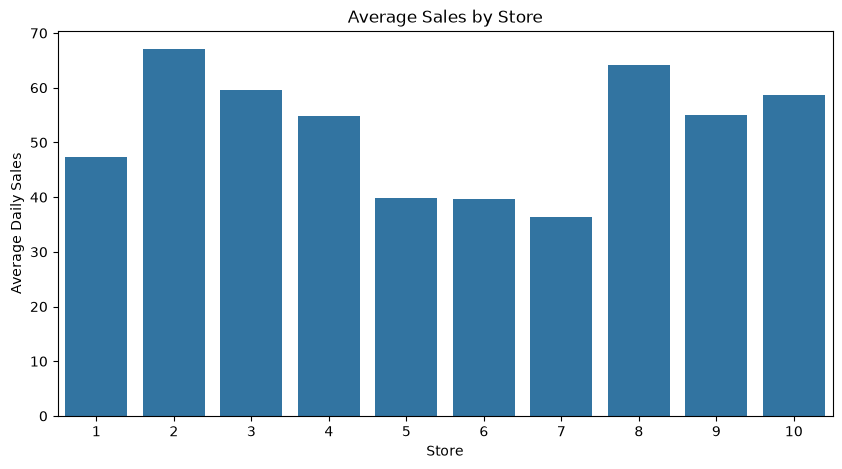

In [26]:
plt.figure(figsize=(10, 5))
sns.barplot(x=store_sales.index, y=store_sales.values)
plt.title("Average Sales by Store")
plt.xlabel("Store")
plt.ylabel("Average Daily Sales")
plt.show()

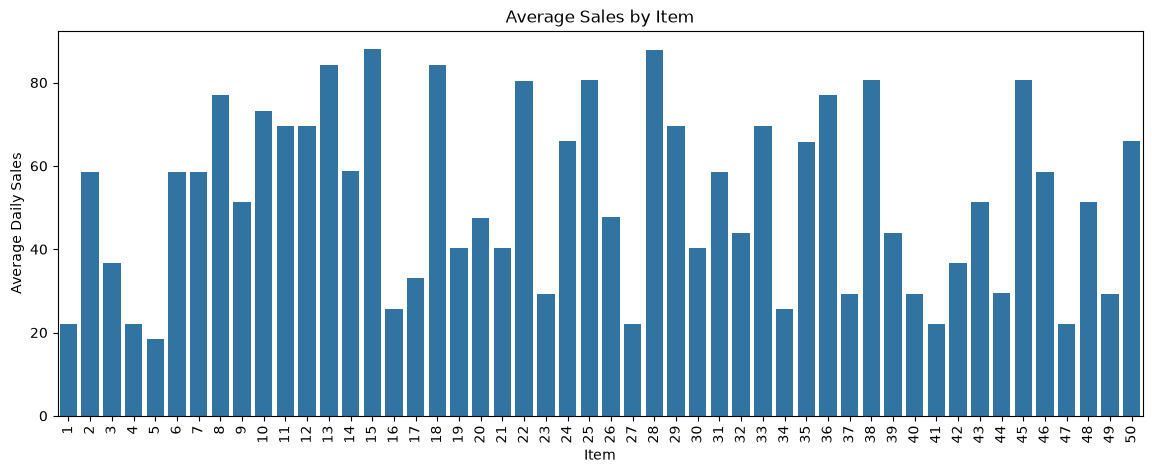

In [27]:
plt.figure(figsize=(14, 5))
sns.barplot(x=item_sales.index, y=item_sales.values)
plt.title("Average Sales by Item")
plt.xlabel("Item")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=90)
plt.show()

In [28]:
sample = df[
    (df['store'] == 7) &
    (df['item'] == 44)
].sort_values('date')

sample.head()

,date,store,item,sales,day_name,month,year
796136,2013-01-01,7,44,6,Tuesday,1,2013
796137,2013-01-02,7,44,15,Wednesday,1,2013
796138,2013-01-03,7,44,7,Thursday,1,2013
796139,2013-01-04,7,44,8,Friday,1,2013
796140,2013-01-05,7,44,15,Saturday,1,2013


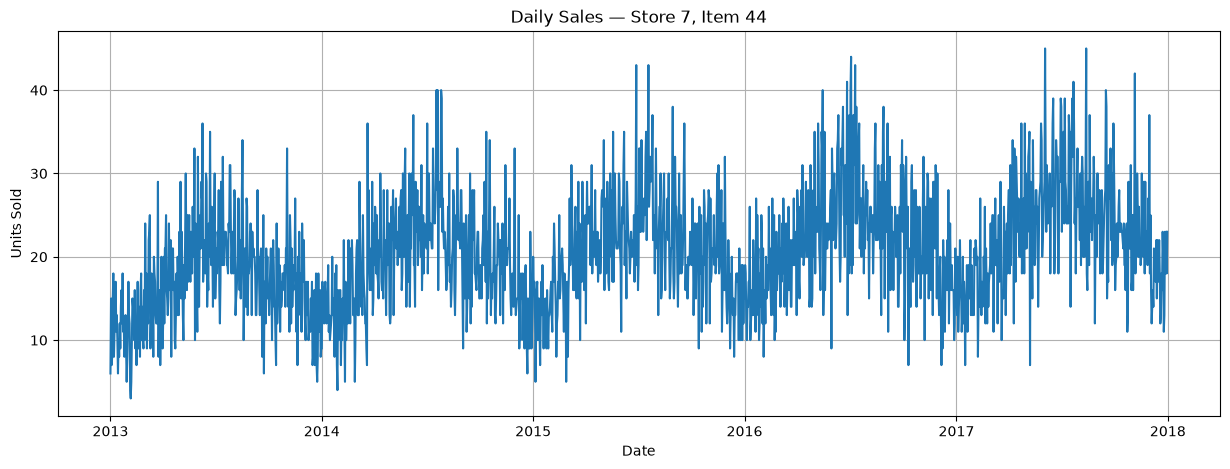

In [29]:
plt.figure(figsize=(15, 5))

plt.plot(sample['date'], sample['sales'])

plt.title("Daily Sales — Store 7, Item 44")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.grid(True)
plt.show()

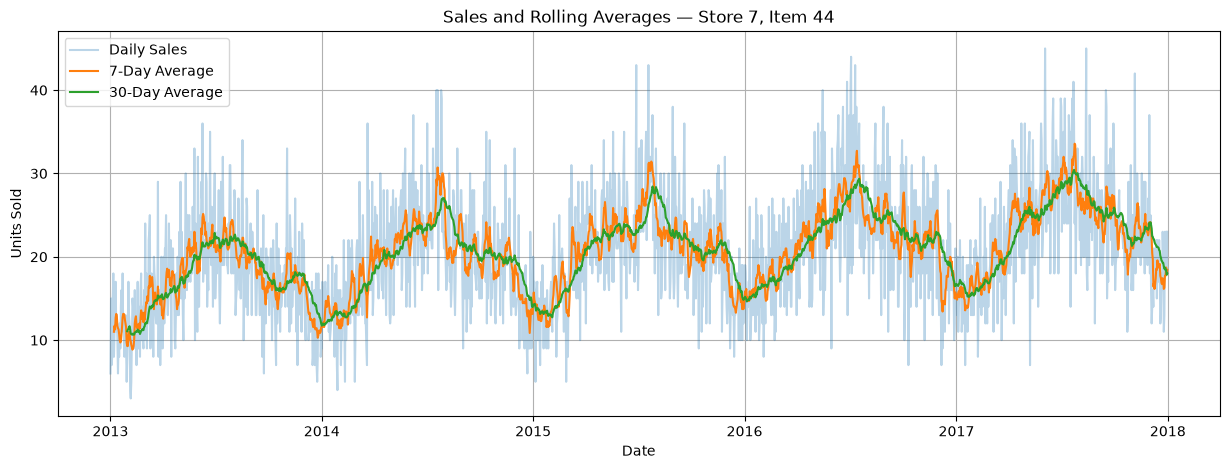

In [30]:
sample = sample.copy()

sample['rolling_7'] = sample['sales'].rolling(7).mean()
sample['rolling_30'] = sample['sales'].rolling(30).mean()

plt.figure(figsize=(15, 5))

plt.plot(sample['date'], sample['sales'], alpha=0.3, label='Daily Sales')
plt.plot(sample['date'], sample['rolling_7'], label='7-Day Average')
plt.plot(sample['date'], sample['rolling_30'], label='30-Day Average')

plt.title("Sales and Rolling Averages — Store 7, Item 44")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)
plt.show()

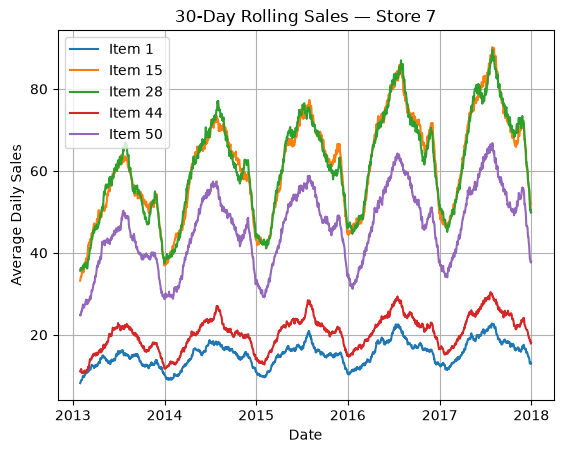

In [31]:
for item in [1, 15, 28, 44, 50]:
    temp = df[
        (df['store'] == 7) &
        (df['item'] == item)
    ]

    plt.plot(temp['date'], temp['sales'].rolling(30).mean(), label=f'Item {item}')

plt.title("30-Day Rolling Sales — Store 7")
plt.xlabel("Date")
plt.ylabel("Average Daily Sales")
plt.legend()
plt.grid(True)
plt.show()

In [32]:
model_df = df[['date', 'store', 'item', 'sales']].copy()

model_df = model_df.sort_values(
    ['store', 'item', 'date']
).reset_index(drop=True)

model_df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [34]:
model_df['dayofweek'] = model_df['date'].dt.day_of_week
model_df['month'] = model_df['date'].dt.month
model_df['dayofyear'] = model_df['date'].dt.day_of_year
model_df['weekofyear'] = model_df['date'].dt.isocalendar().week.astype(int)

In [35]:
model_df[['date', 'dayofweek', 'month', 'dayofyear', 'weekofyear']].head()

,date,dayofweek,month,dayofyear,weekofyear
0,2013-01-01,1,1,1,1
1,2013-01-02,2,1,2,1
2,2013-01-03,3,1,3,1
3,2013-01-04,4,1,4,1
4,2013-01-05,5,1,5,1


In [37]:
model_df.columns.tolist()

['date',
 'store',
 'item',
 'sales',
 'dayofweek',
 'month',
 'dayofyear',
 'weekofyear']

In [38]:
for lag in [91, 98, 105, 182, 364]:
    model_df[f'lag_{lag}'] = (
        model_df.groupby(['store', 'item'])['sales']
        .shift(lag)
    )

In [39]:
grouped_sales = model_df.groupby(['store', 'item'])['sales']

shifted_sales = grouped_sales.shift(91)

model_df['roll_mean_28'] = (
    shifted_sales.groupby(
        [model_df['store'], model_df['item']]
    ).transform(lambda x: x.rolling(28).mean())
)

model_df['roll_mean_90'] = (
    shifted_sales.groupby(
        [model_df['store'], model_df['item']]
    ).transform(lambda x: x.rolling(90).mean())
)

In [40]:
model_df.columns.tolist()

['date',
 'store',
 'item',
 'sales',
 'dayofweek',
 'month',
 'dayofyear',
 'weekofyear',
 'lag_91',
 'lag_98',
 'lag_105',
 'lag_182',
 'lag_364',
 'roll_mean_28',
 'roll_mean_90']

In [41]:
model_df[[
    'date', 'store', 'item', 'sales',
    'lag_91', 'lag_98', 'lag_105',
    'lag_182', 'lag_364',
    'roll_mean_28', 'roll_mean_90'
]].tail(10)

,date,store,item,sales,lag_91,lag_98,lag_105,lag_182,lag_364,roll_mean_28,roll_mean_90
912990,2017-12-22,10,50,75,97.0,94.0,97.0,97.0,64.0,87.357143,96.311111
912991,2017-12-23,10,50,70,97.0,97.0,93.0,129.0,65.0,87.535714,96.200000
912992,2017-12-24,10,50,76,99.0,107.0,96.0,107.0,64.0,86.928571,96.388889
912993,2017-12-25,10,50,51,63.0,61.0,74.0,82.0,61.0,85.678571,96.166667
912994,2017-12-26,10,50,41,79.0,84.0,70.0,83.0,60.0,85.678571,96.033333
912995,2017-12-27,10,50,63,80.0,72.0,84.0,91.0,43.0,85.714286,95.566667
912996,2017-12-28,10,50,59,82.0,89.0,90.0,122.0,68.0,85.464286,95.233333
912997,2017-12-29,10,50,74,90.0,97.0,94.0,112.0,63.0,85.250000,94.911111
912998,2017-12-30,10,50,62,103.0,97.0,97.0,119.0,64.0,85.642857,94.722222
912999,2017-12-31,10,50,82,99.0,99.0,107.0,120.0,69.0,85.535714,94.722222


In [42]:
lag_columns = [
    'lag_91', 'lag_98', 'lag_105',
    'lag_182', 'lag_364',
    'roll_mean_28', 'roll_mean_90'
]

model_df[lag_columns].isnull().sum()

lag_91           45500
lag_98           49000
lag_105          52500
lag_182          91000
lag_364         182000
roll_mean_28     59000
roll_mean_90     90000
dtype: int64

In [43]:
model_df[lag_columns].isnull().sum().sum()

np.int64(569000)

In [44]:
features = [
    'store',
    'item',
    'dayofweek',
    'month',
    'dayofyear',
    'weekofyear',
    'lag_91',
    'lag_98',
    'lag_105',
    'lag_182',
    'lag_364',
    'roll_mean_28',
    'roll_mean_90'
]

target = 'sales'

In [45]:
train_df = model_df[model_df['date'] < '2017-10-01'].copy()

valid_df = model_df[model_df['date'] >= '2017-10-01'].copy()

print("Training shape:", train_df.shape)
print("Validation shape:", valid_df.shape)

print("Training period:",
      train_df['date'].min(), "to", train_df['date'].max())

print("Validation period:",
      valid_df['date'].min(), "to", valid_df['date'].max())

Training shape: (867000, 15)
Validation shape: (46000, 15)
Training period: 2013-01-01 00:00:00 to 2017-09-30 00:00:00
Validation period: 2017-10-01 00:00:00 to 2017-12-31 00:00:00


In [46]:
X_train = train_df[features]
y_train = train_df[target]

X_valid = valid_df[features]
y_valid = valid_df[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

X_train: (867000, 13)
y_train: (867000,)
X_valid: (46000, 13)
y_valid: (46000,)


In [47]:
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [48]:
model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1
)

In [49]:
model.fit(X_train, y_train)

,num_leaves,63
,learning_rate,0.05
,n_estimators,500
,subsample,0.8
,colsample_bytree,0.8
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000
,objective,None


In [51]:
predictions = model.predict(X_valid)

print(predictions[:10])

[26.67257541 19.04386633 20.50159401 22.22935057 22.42095986 23.35728571
 24.79368099 26.17957806 17.78270556 20.27059476]


In [52]:
mae = mean_absolute_error(y_valid, predictions)

rmse = np.sqrt(mean_squared_error(y_valid, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 5.929733177007428
RMSE: 7.692855670907904


In [53]:
denominator = np.abs(y_valid) + np.abs(predictions)

smape = np.mean(
    np.where(
        denominator == 0,
        0,
        2 * np.abs(y_valid - predictions) / denominator
    )
) * 100

print("SMAPE:", smape)

SMAPE: 12.47773964338756


In [54]:
importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
})

importance = importance.sort_values(
    by='importance',
    ascending=False
)

importance

,feature,importance
10,lag_364,5148
12,roll_mean_90,3742
11,roll_mean_28,3680
1,item,3248
4,dayofyear,3040
6,lag_91,2288
3,month,2064
7,lag_98,1766
8,lag_105,1476
2,dayofweek,1467


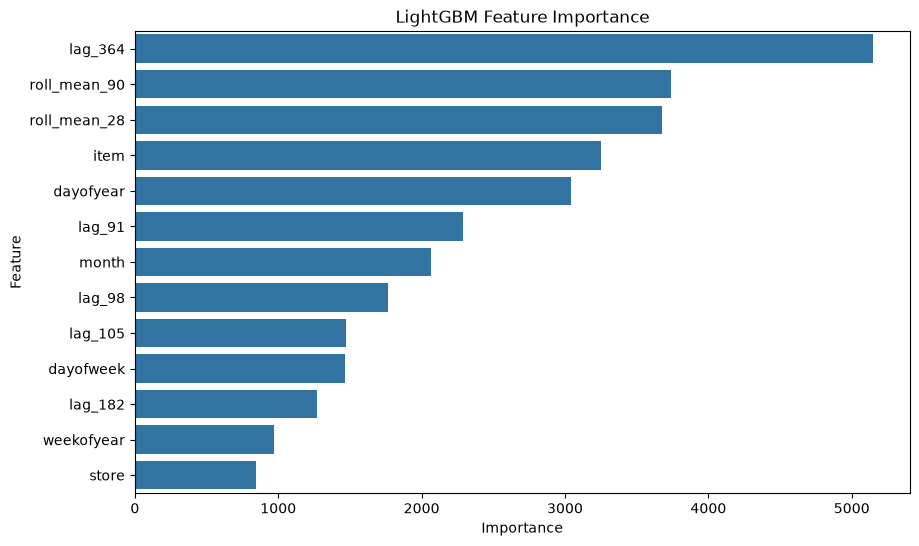

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='importance',
    y='feature'
)

plt.title("LightGBM Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [56]:
import joblib
import os

# Create models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save trained LightGBM model
joblib.dump(model, "models/lgbm_demand.pkl")

# Verify model was saved
if os.path.exists("models/lgbm_demand.pkl"):
    print("Model saved successfully!")
    print("Location: models/lgbm_demand.pkl")
    print("File size:", round(os.path.getsize("models/lgbm_demand.pkl") / (1024 * 1024), 2), "MB")
else:
    print("Model saving failed!")

Model saved successfully!
Location: models/lgbm_demand.pkl
File size: 2.87 MB


In [57]:
valid_predictions = valid_df[
    ['date', 'store', 'item', 'sales']
].copy()

valid_predictions['predicted_sales'] = predictions

valid_predictions.to_csv(
    'data/valid_predictions.csv',
    index=False
)

print("Validation predictions saved!")
print(valid_predictions.head())

Validation predictions saved!
           date  store  item  sales  predicted_sales
1734 2017-10-01      1     1     21        26.672575
1735 2017-10-02      1     1     12        19.043866
1736 2017-10-03      1     1     18        20.501594
1737 2017-10-04      1     1     15        22.229351
1738 2017-10-05      1     1     20        22.420960


In [58]:
history_recent = (
    model_df
    .sort_values('date')
    .groupby(['store', 'item'])
    .tail(30)
    [['date', 'store', 'item', 'sales']]
)

history_recent.to_csv(
    'data/history_recent.csv',
    index=False
)

print("Recent history saved!")
print("Rows:", len(history_recent))

Recent history saved!
Rows: 15000


In [59]:
np.random.seed(42)

item_info = pd.DataFrame({
    'item': range(1, 51)
})

item_info['base_price'] = np.random.uniform(
    100, 500, 50
).round(2)

item_info['unit_cost'] = (
    item_info['base_price'] *
    np.random.uniform(0.55, 0.75, 50)
).round(2)

item_info['elasticity'] = np.random.uniform(
    -2.5, -0.8, 50
).round(2)

item_info.to_csv(
    'data/item_info.csv',
    index=False
)

print(item_info.head())
print("Item information saved!")

   item  base_price  unit_cost  elasticity
0     1      249.82     185.85       -2.45
1     2      480.29     338.62       -1.42
2     3      392.80     289.85       -1.97
3     4      339.46     247.45       -1.64
4     5      162.41     108.75       -0.96
Item information saved!


In [60]:
for file in [
    'models/lgbm_demand.pkl',
    'data/valid_predictions.csv',
    'data/history_recent.csv',
    'data/item_info.csv'
]:
    print(file, ":", os.path.exists(file))

models/lgbm_demand.pkl : True
data/valid_predictions.csv : True
data/history_recent.csv : True
data/item_info.csv : True


In [61]:
# Prepare the latest inventory and demand snapshot

snapshot_date = pd.Timestamp("2017-09-30")

# Get the last 14 days of actual sales for each store-item
recent_14 = (
    model_df[model_df['date'] <= snapshot_date]
    .groupby(['store', 'item'])
    .tail(14)
)

# Calculate average daily demand
avg_daily_demand = (
    recent_14.groupby(['store', 'item'])['sales']
    .mean()
    .reset_index(name='avg_daily_demand')
)

# Merge with item information
pricing_plan = avg_daily_demand.merge(
    item_info,
    on='item',
    how='left'
)

# Calculate forecast demand for 14 days
pricing_plan['forecast_14d_units'] = (
    pricing_plan['avg_daily_demand'] * 14
).round().astype(int)

# Simulate current inventory
pricing_plan['current_stock'] = (
    pricing_plan['avg_daily_demand'] * 10
).round().astype(int)

# Calculate inventory coverage
pricing_plan['cover_days'] = (
    pricing_plan['current_stock'] /
    pricing_plan['avg_daily_demand']
).round(2)

print("Pricing snapshot created!")
print(pricing_plan.head())
print("Total combinations:", len(pricing_plan))

Pricing snapshot created!
   store  item  avg_daily_demand  base_price  unit_cost  elasticity  \
0      1     1         24.428571      249.82     185.85       -2.45   
1      1     2         63.785714      480.29     338.62       -1.42   
2      1     3         39.642857      392.80     289.85       -1.97   
3      1     4         22.071429      339.46     247.45       -1.64   
4      1     5         19.857143      162.41     108.75       -0.96   

   forecast_14d_units  current_stock  cover_days  
0                 342            244        9.99  
1                 893            638       10.00  
2                 555            396        9.99  
3                 309            221       10.01  
4                 278            199       10.02  
Total combinations: 500


In [62]:
# Inventory simulation parameters
REORDER_DAYS = 10
ORDER_UP_TO_DAYS = 25
LEAD_TIME_DAYS = 3

# Simulate current stock between reorder point and order-up-to level
np.random.seed(42)

pricing_plan['current_stock'] = (
    pricing_plan['avg_daily_demand'] *
    np.random.uniform(REORDER_DAYS, ORDER_UP_TO_DAYS, len(pricing_plan))
).round().astype(int)

# Reorder point
pricing_plan['reorder_point'] = (
    pricing_plan['avg_daily_demand'] * REORDER_DAYS
).round().astype(int)

# Order-up-to level
pricing_plan['order_up_to'] = (
    pricing_plan['avg_daily_demand'] * ORDER_UP_TO_DAYS
).round().astype(int)

# Inventory coverage
pricing_plan['cover_days'] = (
    pricing_plan['current_stock'] /
    pricing_plan['avg_daily_demand']
).round(2)

print(pricing_plan.head(10))
print("\nAverage inventory cover:", pricing_plan['cover_days'].mean())

   store  item  avg_daily_demand  base_price  unit_cost  elasticity  \
0      1     1         24.428571      249.82     185.85       -2.45   
1      1     2         63.785714      480.29     338.62       -1.42   
2      1     3         39.642857      392.80     289.85       -1.97   
3      1     4         22.071429      339.46     247.45       -1.64   
4      1     5         19.857143      162.41     108.75       -0.96   
5      1     6         63.071429      162.40     119.26       -2.08   
6      1     7         62.785714      123.23      69.96       -1.80   
7      1     8         85.857143      446.47     263.06       -1.22   
8      1     9         55.357143      340.45     190.33       -2.11   
9      1    10         81.785714      383.23     235.71       -2.37   

   forecast_14d_units  current_stock  cover_days  reorder_point  order_up_to  
0                 342            382       15.64            244          611  
1                 893           1547       24.25            

In [63]:
def recommend_price(row):

    cover = row['cover_days']
    price = row['base_price']
    cost = row['unit_cost']

    if cover < 7:
        change = 0.08
        action = "RAISE"

    elif cover < 9:
        change = 0.03
        action = "RAISE"

    elif cover < 18:
        change = 0
        action = "HOLD"

    elif cover < 22:
        change = -0.05
        action = "DISCOUNT"

    else:
        change = -0.10
        action = "DISCOUNT"

    # Apply maximum movement of 15%
    change = np.clip(change, -0.15, 0.15)

    suggested_price = price * (1 + change)

    # Maintain minimum price floor
    price_floor = cost * 1.15
    suggested_price = max(suggested_price, price_floor)

    # Round final price
    suggested_price = round(suggested_price, 2)

    # Check whether discount is profitable
    if action == "DISCOUNT":
        old_profit = price - cost
        new_profit = suggested_price - cost

        if new_profit < old_profit:
            action = "HOLD_OVERSTOCK"
            suggested_price = price

    return pd.Series({
        'suggested_price': suggested_price,
        'action': action
    })


pricing_plan[['suggested_price', 'action']] = pricing_plan.apply(
    recommend_price,
    axis=1
)

pricing_plan.head(10)

,store,item,avg_daily_demand,base_price,unit_cost,elasticity,forecast_14d_units,current_stock,cover_days,reorder_point,order_up_to,suggested_price,action
0,1,1,24.428571,249.82,185.85,-2.45,342,382,15.64,244,611,249.82,HOLD
1,1,2,63.785714,480.29,338.62,-1.42,893,1547,24.25,638,1595,480.29,HOLD_OVERSTOCK
2,1,3,39.642857,392.80,289.85,-1.97,555,832,20.99,396,991,392.80,HOLD_OVERSTOCK
3,1,4,22.071429,339.46,247.45,-1.64,309,419,18.98,221,552,339.46,HOLD_OVERSTOCK
4,1,5,19.857143,162.41,108.75,-0.96,278,245,12.34,199,496,162.41,HOLD
5,1,6,63.071429,162.40,119.26,-2.08,883,778,12.34,631,1577,162.40,HOLD
6,1,7,62.785714,123.23,69.96,-1.80,879,683,10.88,628,1570,123.23,HOLD
7,1,8,85.857143,446.47,263.06,-1.22,1202,1974,22.99,859,2146,446.47,HOLD_OVERSTOCK
8,1,9,55.357143,340.45,190.33,-2.11,775,1053,19.02,554,1384,340.45,HOLD_OVERSTOCK
9,1,10,81.785714,383.23,235.71,-2.37,1145,1687,20.63,818,2045,383.23,HOLD_OVERSTOCK


In [64]:
pricing_plan['snapshot_date'] = snapshot_date

pricing_plan.to_csv(
    'data/pricing_plan_snapshot.csv',
    index=False
)

print("Pricing snapshot saved successfully!")
print("\nAction distribution:")
print(pricing_plan['action'].value_counts())

print("\nAverage inventory cover:")
print(pricing_plan['cover_days'].mean())

Pricing snapshot saved successfully!

Action distribution:
action
HOLD              262
HOLD_OVERSTOCK    238
Name: count, dtype: int64

Average inventory cover:
17.478199999999998


In [65]:
print("Pricing action distribution:")
print(pricing_plan['action'].value_counts())

print("\nAction percentages:")
print(
    pricing_plan['action']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Pricing action distribution:
action
HOLD              262
HOLD_OVERSTOCK    238
Name: count, dtype: int64

Action percentages:
action
HOLD              52.4
HOLD_OVERSTOCK    47.6
Name: proportion, dtype: float64


In [66]:
for file in [
    'models/lgbm_demand.pkl',
    'data/valid_predictions.csv',
    'data/history_recent.csv',
    'data/item_info.csv',
    'data/pricing_plan_snapshot.csv'
]:
    print(file, os.path.exists(file))

models/lgbm_demand.pkl True
data/valid_predictions.csv True
data/history_recent.csv True
data/item_info.csv True
data/pricing_plan_snapshot.csv True


In [67]:
snapshot_date = pd.Timestamp("2017-09-30")

history_recent = (
    model_df[model_df["date"] <= snapshot_date]
    .sort_values("date")
    .groupby(["store", "item"])
    .tail(30)
    [["date", "store", "item", "sales"]]
)

history_recent.to_csv("data/history_recent.csv", index=False)

print(history_recent["date"].min())
print(history_recent["date"].max())
print(history_recent.shape)

2017-09-01 00:00:00
2017-09-30 00:00:00
(15000, 4)
